In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/creditcard.csv")

print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.info()

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass counts:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Fraud count:", df["Class"].sum())
print("Legit count:", (df["Class"] == 0).sum())
print("All-legit baseline accuracy:", round((df["Class"] == 0).mean(), 4))

Missing values: 0
Duplicate rows: 1081
Fraud count: 492
Legit count: 284315
All-legit baseline accuracy: 0.9983


In [4]:
dups = df[df.duplicated()]
print("Duplicates by class:")
print(dups["Class"].value_counts())

df_clean = df.drop_duplicates().reset_index(drop=True)
print("\nShape before:", df.shape)
print("Shape after:", df_clean.shape)

print("\nClass counts after dropping:")
print(df_clean["Class"].value_counts())
print((df_clean["Class"].value_counts(normalize=True) * 100).round(4))


Duplicates by class:
Class
0    1062
1      19
Name: count, dtype: int64

Shape before: (284807, 31)
Shape after: (283726, 31)

Class counts after dropping:
Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


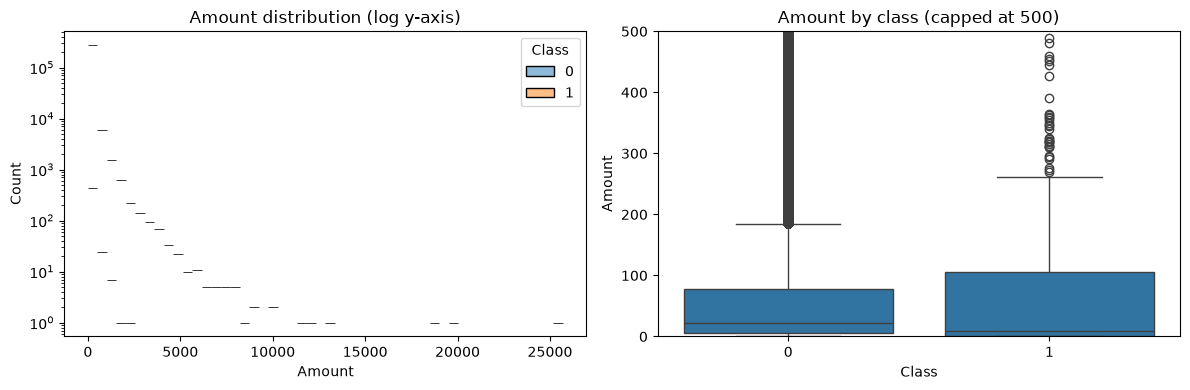

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df_clean.groupby("Class")["Amount"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df_clean, x="Amount", hue="Class", bins=50, log_scale=(False, True), ax=axes[0])
axes[0].set_title("Amount distribution (log y-axis)")

sns.boxplot(data=df_clean, x="Class", y="Amount", ax=axes[1])
axes[1].set_ylim(0, 500)
axes[1].set_title("Amount by class (capped at 500)")

plt.tight_layout()
plt.show()

Time span (hours): 48.0
      transactions  frauds  fraud_rate
Time                                  
0.0           7647       6      0.0008
1.0           4208      10      0.0024
2.0           3308      48      0.0145
3.0           3487      17      0.0049
4.0           2204      23      0.0104
5.0           2988      11      0.0037
6.0           4082       9      0.0022
7.0           7233      23      0.0032
8.0          10232       9      0.0009
9.0          15767      16      0.0010
10.0         16548       8      0.0005
11.0         16781      53      0.0032
12.0         15378      17      0.0011
13.0         15323      17      0.0011
14.0         16520      23      0.0014
15.0         16374      26      0.0016
16.0         16396      22      0.0013
17.0         16130      28      0.0017
18.0         16959      28      0.0017
19.0         15566      19      0.0012
20.0         16705      18      0.0011
21.0         17629      16      0.0009
22.0         15378       9      0.0006
2

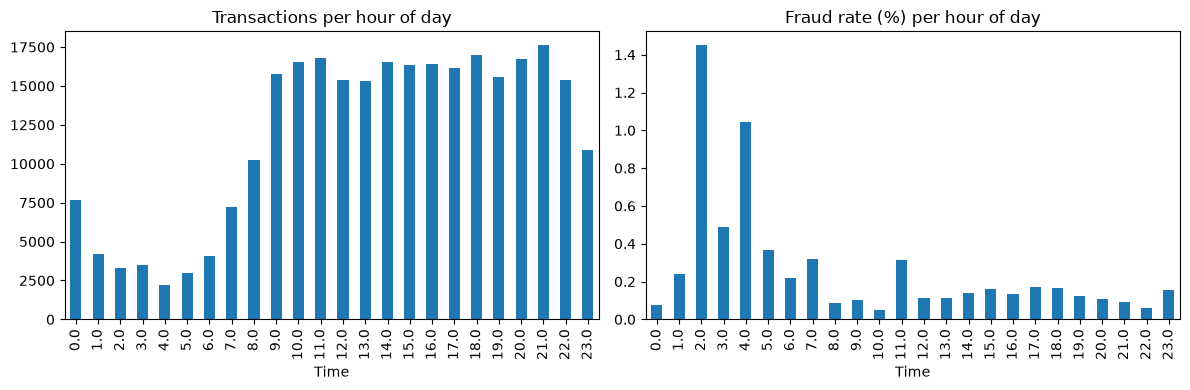

In [7]:
print("Time span (hours):", round(df_clean["Time"].max() / 3600, 1))

hour = (df_clean["Time"] // 3600) % 24
by_hour = df_clean.groupby(hour)["Class"].agg(["count", "sum", "mean"])
by_hour.columns = ["transactions", "frauds", "fraud_rate"]
print(by_hour.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour["transactions"].plot(kind="bar", ax=axes[0], title="Transactions per hour of day")
(by_hour["fraud_rate"] * 100).plot(kind="bar", ax=axes[1], title="Fraud rate (%) per hour of day")
plt.tight_layout()
plt.show()

V17   -0.313
V14   -0.293
V12   -0.251
V10   -0.207
V16   -0.187
V3    -0.182
V7    -0.172
V11    0.149
V4     0.129
V18   -0.105
Name: Class, dtype: float64


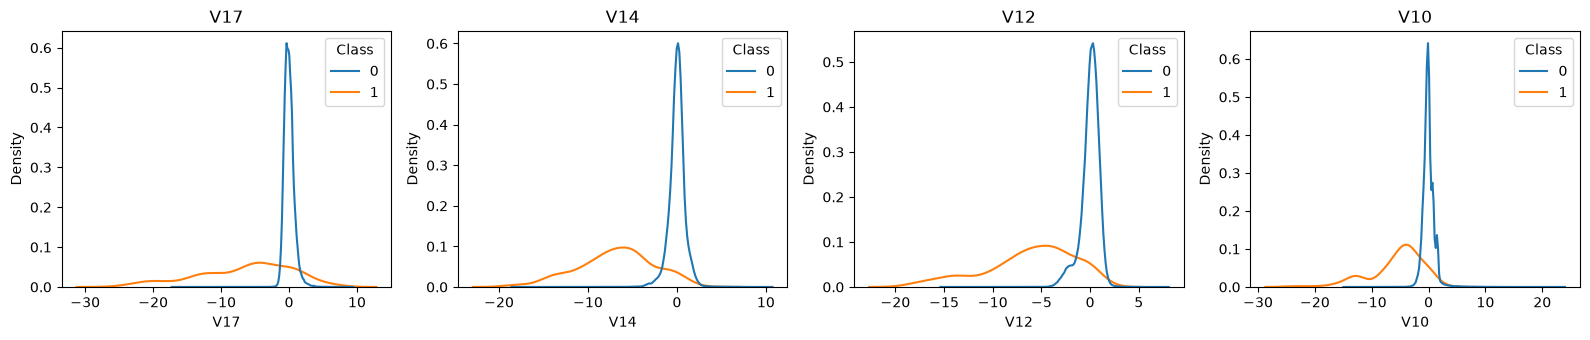

In [8]:
corr = df_clean.drop(columns=["Time"]).corr()["Class"].drop("Class")
corr_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr_sorted.head(10).round(3))

top = corr_sorted.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, top):
    sns.kdeplot(data=df_clean, x=col, hue="Class", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [9]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Class", "Time"])
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nFraud rate in train: ", round(y_train.mean() * 100, 4), "%")
print("Fraud rate in test:  ", round(y_test.mean() * 100, 4), "%")
print("\nFrauds in train:", y_train.sum(), "| Frauds in test:", y_test.sum())

Train: (226980, 29) | Test: (56746, 29)

Fraud rate in train:  0.1665 %
Fraud rate in test:   0.1674 %

Frauds in train: 378 | Frauds in test: 95


In [10]:
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    [("scale_amount", RobustScaler(), ["Amount"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Train Amount after scaling:")
print(X_train_p["Amount"].describe().round(3))
print("\nTest Amount after scaling:")
print(X_test_p["Amount"].describe().round(3))
print("\nMedian learned from train:", preprocessor.named_transformers_["scale_amount"].center_)

Train Amount after scaling:
count    226980.000
mean          0.919
std           3.406
min          -0.306
25%          -0.227
50%           0.000
75%           0.773
max         272.096
Name: Amount, dtype: float64

Test Amount after scaling:
count    56746.000
mean         0.925
std          3.716
min         -0.306
25%         -0.230
50%         -0.007
75%          0.754
max        355.725
Name: Amount, dtype: float64

Median learned from train: [22.08]


## Phase 1 Summary

**Dataset:** (rows, columns, what the features are, what the target is)

**Class imbalance:** (fraud percentage, and why accuracy is misleading)

**Data quality:** (missing values, duplicates found and what I did about them, and why)

**Amount and Time:** (what I found, and why I dropped Time)

**V features:** (what they are, their limitation, and what the correlations told me)

**Split:** (how I split, why stratify, how many frauds in test)

**Preprocessing:** (what I scaled, which scaler, why, and how I avoided leakage)

**Plan for imbalance (Phase 2):** (how I intend to handle it, and what I will NOT do before splitting)